# Predicting Olist Delivery Time

## 1. Goal and success metric

**Business problem.** Olist shows customers an estimated delivery date at checkout. That estimate is far too pessimistic, which hurts conversion. If we can predict delivery time more accurately, Olist can promise earlier dates.

**What we predict (three regression targets, all in days):**

| Target | From | To | What it measures |
|---|---|---|---|
| `leg1` | purchase | carrier pickup | seller handling time |
| `leg2` | carrier pickup | customer delivery | shipping time |
| `total` | purchase | customer delivery | what the customer experiences |

We train one model per target, then check whether `leg1 + leg2` predicted separately beats the direct `total` model.

**Metrics.** MAE (in days) is the main metric because it is easy to explain and is not dominated by a few extreme orders. We also report RMSE and R².

**Baseline.** The score to beat is Olist's current estimate (`order_estimated_delivery_date`).

A feature is allowed only if it is known at the moment of purchase.

## 2. Imports and data loading

In [1]:
import warnings, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings('ignore')
RANDOM_STATE = 42

In [2]:
time_cols = ['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date',
             'order_delivered_customer_date', 'order_estimated_delivery_date']

orders       = pd.read_csv('../data/olist_orders_dataset.csv', parse_dates=time_cols)
items        = pd.read_csv('../data/olist_order_items_dataset.csv', parse_dates=['shipping_limit_date'])
customers    = pd.read_csv('../data/olist_customers_dataset.csv')
sellers      = pd.read_csv('../data/olist_sellers_dataset.csv')
products     = pd.read_csv('../data/olist_products_dataset.csv')
geolocation  = pd.read_csv('../data/olist_geolocation_dataset.csv')
translation  = pd.read_csv('../data/product_category_name_translation.csv')

for name, t in [('orders', orders), ('items', items), ('customers', customers), ('sellers', sellers),
                ('products', products), ('geolocation', geolocation), ('translation', translation)]:
    print(f'{name:12s} {t.shape}')

orders       (99441, 8)
items        (112650, 7)
customers    (99441, 5)
sellers      (3095, 4)
products     (32951, 9)
geolocation  (1000163, 5)
translation  (71, 2)


#### code to make tables readable

In [3]:
pd.set_option('display.max_columns', 40)
pd.set_option('display.float_format', lambda v: f'{v:,.2f}')

#### code for chart styling 

In [4]:
# Chart style: light surface, recessive grid, one hue for one measure
BLUE, ORANGE, GREEN = '#2a78d6', '#eb6834', '#1baf7a'
INK, INK2, MUTED, GRID = '#0b0b0b', '#52514e', '#898781', '#e1e0d9'
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': INK2, 'axes.titlecolor': INK,
    'axes.titlesize': 13, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'xtick.color': MUTED, 'ytick.color': MUTED, 'text.color': INK2,
    'legend.frameon': False, 'figure.dpi': 100, 'font.size': 10,
})

## 3. Building one row per order

Each row of the final table is one order, so an order can never appear in both train and test. We keep only orders that were actually delivered and have both timestamps needed for the targets, then compute the three targets.

In [5]:
funnel = [('All orders', len(orders))]

df = orders[orders['order_status'] == 'delivered'].copy()
funnel.append(('Status is delivered', len(df)))

df = df.dropna(subset=['order_delivered_carrier_date', 'order_delivered_customer_date'])
funnel.append(('Has carrier and customer delivery dates', len(df)))

day = pd.Timedelta(days=1)
df['total'] = (df['order_delivered_customer_date'] - df['order_purchase_timestamp']) / day
df['leg1']  = (df['order_delivered_carrier_date']  - df['order_purchase_timestamp']) / day
df['leg2']  = (df['order_delivered_customer_date'] - df['order_delivered_carrier_date']) / day

df = df[(df['leg1'] >= 0) & (df['leg2'] >= 0)]
funnel.append(('Timestamps in logical order (no negative leg)', len(df)))

Now the customer, item, product and seller information. An order can contain several items, so items are aggregated to one row per order.

In [6]:
# customer side
df = df.merge(customers[['customer_id', 'customer_zip_code_prefix', 'customer_state']], on='customer_id', how='left')

# item side: attach product and seller info, then collapse to one row per order
it = (items
      .merge(products[['product_id', 'product_category_name', 'product_weight_g',
                       'product_length_cm', 'product_height_cm', 'product_width_cm']], on='product_id', how='left')
      .merge(translation, on='product_category_name', how='left')
      .merge(sellers[['seller_id', 'seller_zip_code_prefix', 'seller_state']], on='seller_id', how='left'))
it['volume_cm3'] = it['product_length_cm'] * it['product_height_cm'] * it['product_width_cm']

per_order = it.groupby('order_id').agg(
    price=('price', 'sum'),
    freight=('freight_value', 'sum'),
    weight=('product_weight_g', 'sum'),
    volume=('volume_cm3', 'sum'),
    n_items=('order_item_id', 'count'),
    n_sellers=('seller_id', 'nunique'),
    shipping_limit=('shipping_limit_date', 'max'),
    category=('product_category_name_english', 'first'),
    seller_state=('seller_state', 'first'),
    seller_zip=('seller_zip_code_prefix', 'first'),
).reset_index()

df = df.merge(per_order, on='order_id', how='inner')
funnel.append(('Has at least one item', len(df)))

pd.DataFrame(funnel, columns=['step', 'orders']).assign(dropped=lambda t: -t['orders'].diff().fillna(0).astype(int))

,step,orders,dropped
0,All orders,99441,0
1,Status is delivered,96478,2963
2,Has carrier and customer delivery dates,96469,9
3,Timestamps in logical order (no negative leg),96281,188
4,Has at least one item,96281,0


**Distance between seller and customer.** The geolocation table has many coordinates per zip prefix, so we average them into one point per prefix, then compute the great-circle (haversine) distance in km.

In [7]:
zip_xy = geolocation.groupby('geolocation_zip_code_prefix')[['geolocation_lat', 'geolocation_lng']].mean()

df = (df.join(zip_xy.rename(columns={'geolocation_lat': 'c_lat', 'geolocation_lng': 'c_lng'}), on='customer_zip_code_prefix')
        .join(zip_xy.rename(columns={'geolocation_lat': 's_lat', 'geolocation_lng': 's_lng'}), on='seller_zip'))

def haversine_km(lat1, lng1, lat2, lng2):
    lat1, lng1, lat2, lng2 = map(np.radians, [lat1, lng1, lat2, lng2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lng2 - lng1) / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(a))

df['distance_km'] = haversine_km(df['s_lat'], df['s_lng'], df['c_lat'], df['c_lng'])
print('Orders without a distance (zip prefix not in geolocation):', df['distance_km'].isna().sum())
df['category'] = df['category'].fillna('unknown')
print('Final table:', df.shape)

Orders without a distance (zip prefix not in geolocation): 478
Final table: (96281, 28)


## 4. Cleaning and outliers

In [8]:
print('Missing values per column (only columns with gaps):')
miss = df.isna().sum()
miss[miss > 0]

Missing values per column (only columns with gaps):


order_approved_at     14
c_lat                264
c_lng                264
s_lat                215
s_lng                215
distance_km          478
dtype: int64

In [9]:
df[['total', 'leg1', 'leg2']].describe().T

,count,mean,std,min,25%,50%,75%,max
total,"96,281.00",12.57,9.55,0.53,6.78,10.23,15.73,209.63
leg1,"96,281.00",3.23,3.55,0.00,1.13,2.20,4.07,125.78
leg2,"96,281.00",9.33,8.75,0.00,4.10,7.10,12.03,205.19


In [10]:
df[['total', 'leg1', 'leg2']].describe(percentiles=[.5, .9, .99]).T

,count,mean,std,min,50%,90%,99%,max
total,"96,281.00",12.57,9.55,0.53,10.23,23.11,46.06,209.63
leg1,"96,281.00",3.23,3.55,0.00,2.20,6.40,17.72,125.78
leg2,"96,281.00",9.33,8.75,0.00,7.10,18.91,40.99,205.19


In [11]:
print('Orders with total > 100 days:', (df['total'] > 100).sum(), f"({(df['total'] > 100).mean():.2%})")
print('Orders with total > 60 days: ', (df['total'] > 60).sum())

Orders with total > 100 days: 64 (0.07%)
Orders with total > 60 days:  306


**Insight:** The final table has **96,281 orders** (96.8% of all orders). Almost all losses are orders that were never delivered (2,963). Missing values are minor: coordinates are missing for about 200-260 zip prefixes, which leaves 478 orders without a distance. Only 64 orders (0.07%) took more than 100 days, but they can distort a model trained to fit averages, so they are excluded from training only.

**Decisions**
- Missing product size/weight and missing distances are **not** filled now. They are filled later inside the pipeline, using values learned from the training set only.
- Orders with `total` > 100 days are removed **from the training set only** (decided after the split). The test set keeps them, because real customers like these exist and the model should be judged on them.

## 5. EDA

### 5.1 How long do deliveries take, and what does Olist promise?

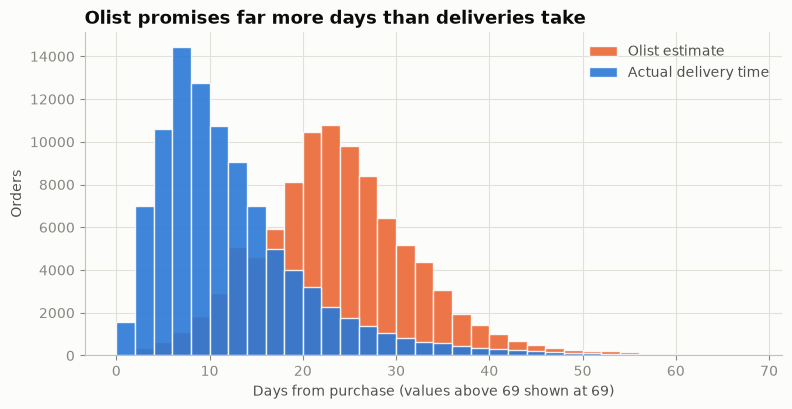

,mean,median
total,12.57,10.23
estimate,23.74,23.23


In [12]:
df['estimate'] = (df['order_estimated_delivery_date'] - df['order_purchase_timestamp']) / day

fig, ax = plt.subplots(figsize=(9, 4.2))
bins = np.arange(0, 70, 2)
ax.hist(df['estimate'].clip(upper=69), bins=bins, color=ORANGE, alpha=0.9, label='Olist estimate', edgecolor='#fcfcfb')
ax.hist(df['total'].clip(upper=69), bins=bins, color=BLUE, alpha=0.9, label='Actual delivery time', edgecolor='#fcfcfb')
ax.set_title('Olist promises far more days than deliveries take')
ax.set_xlabel('Days from purchase (values above 69 shown at 69)'); ax.set_ylabel('Orders')
ax.legend()
plt.show()

df[['total', 'estimate']].agg(['mean', 'median']).T

**Insight:** Olist's estimate is on average **23.7 days**, while orders really arrive in **12.6 days** on average (median 10.2). The two distributions barely overlap: the estimate is a long safety margin, not a prediction. This gap is the opportunity of the project.

### 5.2 Which part of the journey takes the time?

In [13]:
legs = df[['leg1', 'leg2', 'total']].agg(['mean', 'median']).T
legs['share_of_total_mean'] = legs['mean'] / legs.loc['total', 'mean']
legs

,mean,median,share_of_total_mean
leg1,3.23,2.20,0.26
leg2,9.33,7.10,0.74
total,12.57,10.23,1.00


**Insight:** Shipping (`leg2`) is **74%** of the total time (9.3 of 12.6 days on average); seller handling (`leg1`) is only 26% (3.2 days). Most of the predictable variation should therefore come from where the parcel goes, not from how fast the seller packs it.

### 5.3 Distance

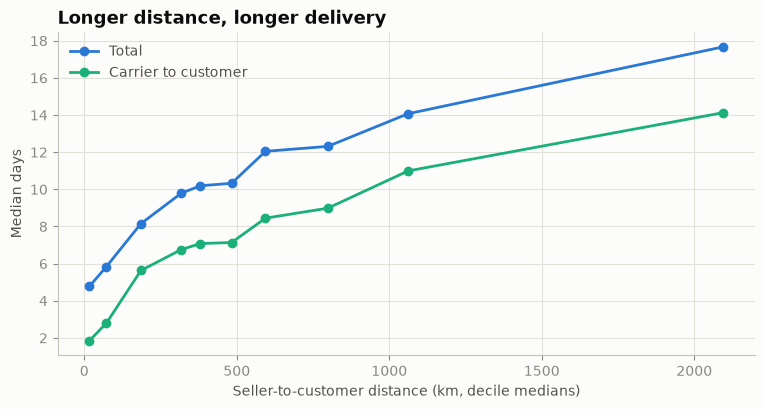

,median_km,median_total,median_leg2
distance_band,,,
"(-0.001, 34.38]",16.50,4.80,1.80
"(34.38, 115.933]",72.70,5.80,2.80
"(115.933, 276.462]",185.70,8.20,5.60
"(276.462, 347.876]",317.50,9.80,6.80
"(347.876, 433.677]",380.60,10.20,7.10
"(433.677, 529.67]",482.90,10.30,7.10
"(529.67, 694.688]",594.10,12.00,8.40
"(694.688, 876.583]",798.30,12.30,9.00
"(876.583, 1457.025]","1,061.90",14.10,11.00


In [14]:
tmp = df.dropna(subset=['distance_km']).copy()
tmp['distance_band'] = pd.qcut(tmp['distance_km'], 10)
by_dist = tmp.groupby('distance_band', observed=True).agg(median_km=('distance_km', 'median'),
                                                          median_total=('total', 'median'),
                                                          median_leg2=('leg2', 'median'))
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(by_dist['median_km'], by_dist['median_total'], marker='o', color=BLUE, lw=2, label='Total')
ax.plot(by_dist['median_km'], by_dist['median_leg2'], marker='o', color=GREEN, lw=2, label='Carrier to customer')
ax.set_title('Longer distance, longer delivery')
ax.set_xlabel('Seller-to-customer distance (km, decile medians)'); ax.set_ylabel('Median days')
ax.legend()
plt.show()

by_dist.round(1)

**Insight:** Delivery time rises steadily with distance: the nearest 10% of orders take a median of **4.8 days**, the farthest 10% take **17.7 days**. The curve flattens between about 300 and 500 km, then keeps rising. Distance has the strongest correlation with delivery time of all numeric features (0.39, section 5.6).

### 5.4 Geography

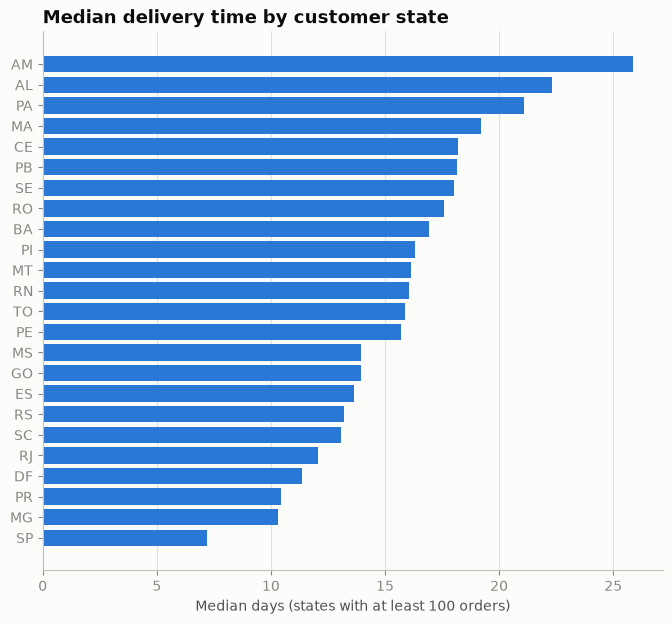

,size,median,mean
same_state,,,
False,61642,12.80,15.16
True,34639,6.56,7.95


In [15]:
st = (df.groupby('customer_state').agg(orders=('total', 'size'), median_total=('total', 'median'))
        .query('orders >= 100').sort_values('median_total'))
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(st.index, st['median_total'], color=BLUE)
ax.set_title('Median delivery time by customer state')
ax.set_xlabel('Median days (states with at least 100 orders)')
ax.grid(axis='y', visible=False)
plt.show()

same = (df['customer_state'] == df['seller_state']).rename('same_state')
df.groupby(same)['total'].agg(['size', 'median', 'mean'])

**Insight:** Location matters a lot. Customers in AM, AL and PA wait about 21-26 days (median), while SP customers wait about 7. Orders where seller and customer are in the same state take a median of **6.6 days** against **12.8** for cross-state orders, so `same_state` should be a strong feature.

### 5.5 Time of year

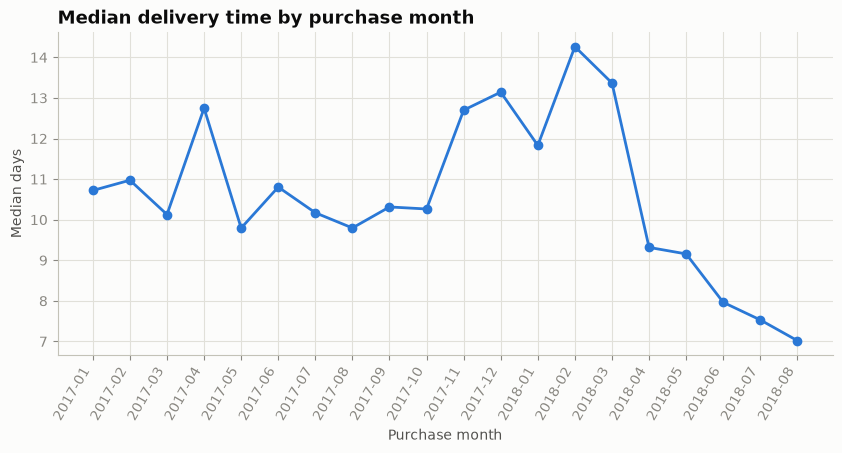

purchase_month,2017-01,2017-02,2017-03,2017-04,2017-05,2017-06,2017-07,2017-08,2017-09,2017-10,2017-11,2017-12,2018-01,2018-02,2018-03,2018-04,2018-05,2018-06,2018-07,2018-08
orders,749.00,"1,651.00","2,545.00","2,303.00","3,544.00","3,134.00","3,861.00","4,191.00","4,149.00","4,478.00","7,288.00","5,513.00","7,069.00","6,555.00","7,003.00","6,791.00","6,719.00","6,050.00","6,119.00","6,306.00"
median_total,10.70,11.00,10.10,12.70,9.80,10.80,10.20,9.80,10.30,10.30,12.70,13.10,11.80,14.30,13.40,9.30,9.20,8.00,7.50,7.00
mean_estimate,39.50,31.90,24.70,27.30,24.30,24.00,23.30,23.50,22.40,23.00,22.60,27.70,26.30,24.50,22.00,23.70,22.90,27.80,19.70,15.20


In [16]:
df['purchase_month'] = df['order_purchase_timestamp'].dt.to_period('M')
mth = df.groupby('purchase_month').agg(orders=('total', 'size'), median_total=('total', 'median'), mean_estimate=('estimate', 'mean'))
mth = mth[mth['orders'] >= 300]

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(mth.index.astype(str), mth['median_total'], marker='o', color=BLUE, lw=2)
ax.set_title('Median delivery time by purchase month')
ax.set_xlabel('Purchase month'); ax.set_ylabel('Median days')
plt.xticks(rotation=60, ha='right')
plt.show()

mth.round(1).T

**Insight:** Through 2017 the median stays around 10-11 days. From **November 2017 to March 2018** it rises to 12-14 days (the peak is February 2018, 14.3 days), and from April 2018 it falls sharply to **7 days** by August 2018. Delivery time depends on the period, so `month` should help, but see the limits discussed in section 13.

### 5.6 Order size and price

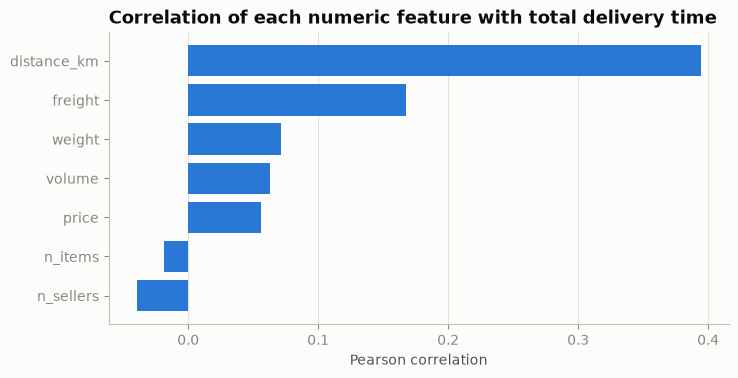

,corr_with_total
n_sellers,-0.04
n_items,-0.02
price,0.06
volume,0.06
weight,0.07
freight,0.17
distance_km,0.39


In [17]:
num_eda = ['price', 'freight', 'weight', 'volume', 'n_items', 'n_sellers', 'distance_km']
corr = df[num_eda + ['total']].corr()['total'].drop('total').sort_values()

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(corr.index, corr.values, color=BLUE)
ax.set_title('Correlation of each numeric feature with total delivery time')
ax.set_xlabel('Pearson correlation'); ax.grid(axis='y', visible=False)
plt.show()

corr.to_frame('corr_with_total')

**Insight:** Only `distance_km` (0.39) and `freight` (0.17) have a visible linear relationship with delivery time. Price, weight and volume are almost unrelated (below 0.07), and `n_items` / `n_sellers` are slightly negative. Freight is largely a proxy for distance, so it is not independent information.

## 6. Feature engineering

Everything below is known at purchase time. Nothing from after the order is placed is used as a feature.

| Feature | Meaning |
|---|---|
| `distance_km` | seller to customer great-circle distance |
| `same_state` | 1 if seller and customer are in the same state |
| `volume`, `weight`, `price`, `freight` | order totals |
| `n_items`, `n_sellers` | order complexity (more sellers means more shipments) |
| `limit_days` | days between purchase and the seller's shipping deadline (the seller's promised handling time) |
| `month`, `weekday`, `hour` | when the order was placed |
| `customer_state`, `seller_state`, `category` | categorical context |

In [18]:
df['same_state'] = (df['customer_state'] == df['seller_state']).astype(int)
df['limit_days'] = (df['shipping_limit'] - df['order_purchase_timestamp']) / day
df['month']      = df['order_purchase_timestamp'].dt.month
df['weekday']    = df['order_purchase_timestamp'].dt.weekday
df['hour']       = df['order_purchase_timestamp'].dt.hour

cat_cols = ['customer_state', 'seller_state', 'category']
num_cols = ['price', 'freight', 'weight', 'volume', 'n_items', 'n_sellers',
            'distance_km', 'same_state', 'limit_days', 'month', 'weekday', 'hour']
features = cat_cols + num_cols
targets  = ['total', 'leg1', 'leg2']

df[num_cols].describe().T[['count', 'mean', 'min', '50%', 'max']]

,count,mean,min,50%,max
price,"96,281.00",137.07,0.85,86.50,"13,440.00"
freight,"96,281.00",22.78,0.00,17.17,"1,794.96"
weight,"96,281.00","2,386.83",0.00,750.00,"184,400.00"
volume,"96,281.00","17,332.06",0.00,"7,245.00","1,476,000.00"
n_items,"96,281.00",1.14,1.00,1.00,21.00
n_sellers,"96,281.00",1.01,1.00,1.00,5.00
distance_km,"95,803.00",600.67,0.00,433.68,"8,677.91"
same_state,"96,281.00",0.36,0.00,0.00,1.00
limit_days,"96,281.00",6.58,2.00,6.01,"1,052.00"
month,"96,281.00",6.03,1.00,6.00,12.00


**Insight:** `same_state` is 1 for 36% of orders. `limit_days` (the seller's shipping deadline) has a median of about 6 days but a maximum above 1,000, so a few extreme values exist; tree models are not bothered by them, but the linear model may be. 478 orders have no distance and are imputed inside the pipelines.

## 7. Train / validation / test split

First 20% of all orders are set aside as the **test set**. The remaining 80% is split again, 20% validation and 80% train, giving roughly 64% / 16% / 20%. The test set is only touched at the very end.

In [19]:
df_tv, df_test = train_test_split(df, test_size=0.2, random_state=RANDOM_STATE)
df_train, df_val = train_test_split(df_tv, test_size=0.2, random_state=RANDOM_STATE)

for name, part in [('train', df_train), ('val', df_val), ('test', df_test)]:
    print(f'{name:5s} {len(part):>7,}  ({len(part)/len(df):.1%})   mean total = {part["total"].mean():.2f} days')

# outliers are removed from the data used to FIT models, never from val/test
OUTLIER_DAYS = 100
fit_train = df_train[df_train['total'] <= OUTLIER_DAYS]
fit_tv    = df_tv[df_tv['total'] <= OUTLIER_DAYS]
print(f'\nTraining rows after dropping total > {OUTLIER_DAYS} days: {len(fit_train):,} (removed {len(df_train) - len(fit_train)})')

train  61,619  (64.0%)   mean total = 12.57 days
val    15,405  (16.0%)   mean total = 12.66 days
test   19,257  (20.0%)   mean total = 12.49 days

Training rows after dropping total > 100 days: 61,574 (removed 45)


## 8. Baseline score: Olist's current estimate

The estimate Olist shows today, converted to days after purchase. It needs no training, so it can be scored on the validation and test rows directly. Every model must beat these numbers.

In [20]:
def score(y_true, y_pred):
    return {'MAE': mean_absolute_error(y_true, y_pred),
            'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
            'R2': r2_score(y_true, y_pred)}

baseline = pd.DataFrame({'val': score(df_val['total'], df_val['estimate']),
                         'test': score(df_test['total'], df_test['estimate'])}).T
baseline

,MAE,RMSE,R2
val,12.79,15.19,-1.46
test,12.72,15.00,-1.60


**Insight:** Olist's current estimate has a **test MAE of 12.72 days**, and a negative R² (-1.60), meaning that using its estimate is worse than predicting the average delivery time. Its estimate is also far above real delivery times (section 5.1). The models must beat the 12.72 days MAE.

## 9. Preprocessing pipelines

Two pipelines, because the two model families need different input:

- **Linear Regression**: missing values imputed, rare categories grouped, categories one-hot encoded, numbers scaled.
- **Histogram Gradient Boosting**: no scaling needed and it handles missing numbers itself. Categories are turned into integer codes and flagged as categorical so the model treats them as groups, not as ordered numbers.

All fitted steps (imputer, scaler, encoders) learn from the training data only, because they live inside the pipeline.

In [21]:
def make_linear():
    cat = Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                    ('ohe', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=200))])
    num = Pipeline([('imp', SimpleImputer(strategy='median')),
                    ('scale', StandardScaler())])
    prep = ColumnTransformer([('cat', cat, cat_cols), ('num', num, num_cols)])
    return Pipeline([('prep', prep), ('model', LinearRegression())])

def make_hgb(**params):
    cat = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1, encoded_missing_value=-1)
    prep = ColumnTransformer([('cat', cat, cat_cols), ('num', 'passthrough', num_cols)])
    # categorical columns come first in the transformed array, so they are the first len(cat_cols) columns
    cat_mask = [True] * len(cat_cols) + [False] * len(num_cols)
    model = HistGradientBoostingRegressor(loss='absolute_error', categorical_features=cat_mask,
                                          random_state=RANDOM_STATE, **params)
    return Pipeline([('prep', prep), ('model', model)])

make_hgb()

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output 

## 10. Models: Linear Regression vs Histogram Gradient Boosting

One model per target and per family (6 models). The weak model (Linear Regression) shows what a simple straight-line relationship can do. The strong one (Histogram Gradient Boosting, trained to minimize MAE directly) shows what non-linear patterns add. Scores below are on the **validation** set.

In [22]:
rows, fitted = [], {}
for t in targets:
    for name, maker in [('Linear Regression', make_linear), ('HistGradientBoosting', make_hgb)]:
        pipe = maker().fit(fit_train[features], fit_train[t])
        fitted[(t, name)] = pipe
        rows.append({'target': t, 'model': name, **score(df_val[t], pipe.predict(df_val[features]))})

val_results = pd.DataFrame(rows).set_index(['target', 'model'])
val_results

MAE  RMSE   R2
target model                               
total  Linear Regression    5.21  8.38 0.25
       HistGradientBoosting 4.51  8.08 0.30
leg1   Linear Regression    1.98  3.29 0.14
       HistGradientBoosting 1.61  3.17 0.21
leg2   Linear Regression    4.51  7.66 0.26
       HistGradientBoosting 3.87  7.45 0.30

**Insight:** On validation, Histogram Gradient Boosting beats Linear Regression for every target (total MAE 4.52 vs 5.21). Both are already far below the 12.7 days of Olist's estimate. R² is only 0.25-0.30, so a lot of variation remains unexplained: delays caused by carrier problems, strikes, weather or customer absence cannot be seen from information available at purchase.

## 11. Hyperparameter tuning

Only the strong model has settings worth tuning. A separate randomized search is run for each target (8 random combinations, 3-fold cross-validation, scored by MAE), on the training rows only.

In [23]:
param_dist = {
    'model__learning_rate':     [0.03, 0.05, 0.08, 0.1, 0.15],
    'model__max_iter':          [150, 300, 500],
    'model__max_leaf_nodes':    [15, 31, 63],
    'model__min_samples_leaf':  [20, 50, 100],
    'model__l2_regularization': [0, 1, 10],
}

searches = {}
for t in targets:
    s = RandomizedSearchCV(make_hgb(), param_dist, n_iter=8, cv=3, scoring='neg_mean_absolute_error',
                           n_jobs=2, random_state=RANDOM_STATE)
    s.fit(fit_train[features], fit_train[t])
    searches[t] = s
    print(f'{t:6s} best CV MAE = {-s.best_score_:.3f}   best params = {s.best_params_}')

total  best CV MAE = 4.370   best params = {'model__min_samples_leaf': 100, 'model__max_leaf_nodes': 63, 'model__max_iter': 150, 'model__learning_rate': 0.08, 'model__l2_regularization': 10}
leg1   best CV MAE = 1.556   best params = {'model__min_samples_leaf': 50, 'model__max_leaf_nodes': 63, 'model__max_iter': 300, 'model__learning_rate': 0.08, 'model__l2_regularization': 0}
leg2   best CV MAE = 3.740   best params = {'model__min_samples_leaf': 100, 'model__max_leaf_nodes': 63, 'model__max_iter': 150, 'model__learning_rate': 0.08, 'model__l2_regularization': 10}


In [24]:
rows = []
for t in targets:
    default = fitted[(t, 'HistGradientBoosting')]
    tuned = searches[t].best_estimator_
    rows.append({'target': t,
                 'val MAE default': mean_absolute_error(df_val[t], default.predict(df_val[features])),
                 'val MAE tuned':   mean_absolute_error(df_val[t], tuned.predict(df_val[features]))})
pd.DataFrame(rows).set_index('target')

,val MAE default,val MAE tuned
target,,
total,4.51,4.48
leg1,1.61,1.57
leg2,3.87,3.85


**Insight:** Tuning helps only slightly (total 4.52 to 4.49 days, leg1 1.60 to 1.57, leg2 3.87 to 3.84). Two of the three searches picked the same settings and all three chose the largest `max_leaf_nodes` offered (63), so a wider search might gain a little more, but the model is already near what this feature set can give.

## 12. Final evaluation on the test set

Now that the settings are chosen, each model is refit on train + validation (outliers removed as before) and scored **once** on the untouched test set.

In [25]:
final = {}
for t in targets:
    final[(t, 'Linear Regression')] = make_linear().fit(fit_tv[features], fit_tv[t])
    best = clone(searches[t].best_estimator_)
    final[(t, 'HistGradientBoosting')] = best.fit(fit_tv[features], fit_tv[t])

pred = {k: m.predict(df_test[features]) for k, m in final.items()}
y_test = df_test['total']

rows = {'Olist estimate (baseline)': score(y_test, df_test['estimate'])}
for name in ['Linear Regression', 'HistGradientBoosting']:
    rows[f'{name}: direct total'] = score(y_test, pred[('total', name)])
    rows[f'{name}: leg1 + leg2'] = score(y_test, pred[('leg1', name)] + pred[('leg2', name)])
results = pd.DataFrame(rows).T
results

,MAE,RMSE,R2
Olist estimate (baseline),12.72,15.00,-1.60
Linear Regression: direct total,5.12,8.06,0.25
Linear Regression: leg1 + leg2,5.12,8.06,0.25
HistGradientBoosting: direct total,4.33,7.63,0.33
HistGradientBoosting: leg1 + leg2,4.35,7.78,0.30


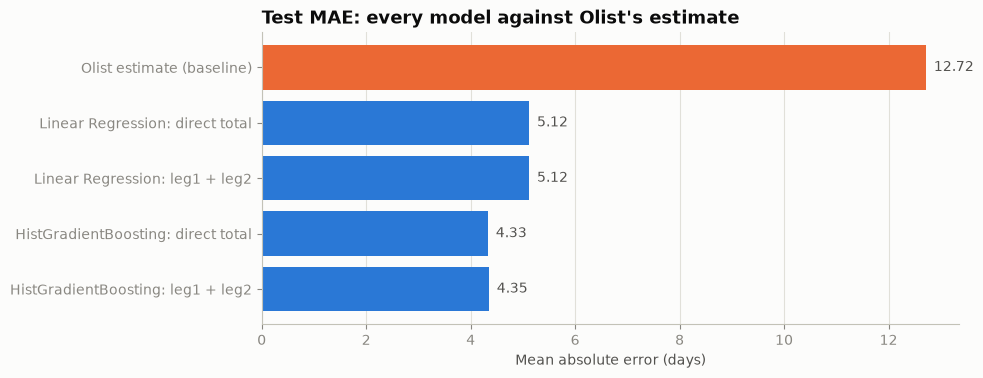

In [26]:
fig, ax = plt.subplots(figsize=(9, 3.8))
labels = results.index[::-1]
vals = results['MAE'][::-1]
ax.barh(labels, vals, color=[ORANGE if 'Olist' in l else BLUE for l in labels])
for y, v in enumerate(vals):
    ax.text(v + 0.15, y, f'{v:.2f}', va='center', color=INK2)
ax.set_title('Test MAE: every model against Olist\'s estimate')
ax.set_xlabel('Mean absolute error (days)'); ax.grid(axis='y', visible=False)
plt.show()

In [27]:
leg_rows = []
for t in ['leg1', 'leg2']:
    for name in ['Linear Regression', 'HistGradientBoosting']:
        leg_rows.append({'target': t, 'model': name, **score(df_test[t], pred[(t, name)])})
pd.DataFrame(leg_rows).set_index(['target', 'model'])

MAE  RMSE   R2
target model                               
leg1   Linear Regression    1.94  3.17 0.16
       HistGradientBoosting 1.54  3.04 0.23
leg2   Linear Regression    4.45  7.32 0.26
       HistGradientBoosting 3.73  7.01 0.32

**Insight:**
- **The best model (direct total, Histogram Gradient Boosting) has a test MAE of 4.33 days against 12.72 for Olist's estimate, a 66% reduction.** R² is 0.33 against -1.60.
- Predicting the two legs separately and adding them (4.35) gives practically the same error as the direct model (4.33). The direct model is simpler and slightly better, so the two-leg route adds no accuracy. For Linear Regression the two numbers are identical (5.12): for a linear model, the sum of two fitted models on the same features is mathematically the same as one model fitted on the sum.
- Separately, the legs are predicted with MAE 1.54 (handling) and 3.73 (shipping). Shipping holds most of the error, consistent with it being 74% of the time.

## 13. Error analysis

Using the final HistGradientBoosting model for `total`. Residual = actual - predicted, so a positive residual is an order that arrived later than predicted.

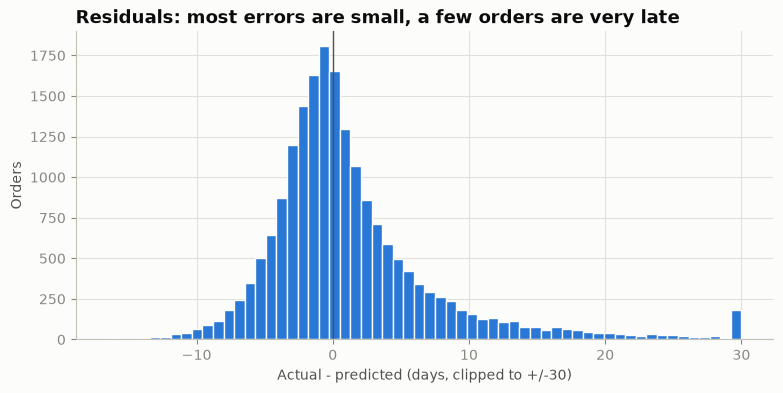

,count,mean,std,min,5%,50%,95%,max
residual (days),"19,257.00",1.41,7.50,-16.55,-6.07,-0.09,13.71,173.67


In [28]:
err = df_test[['total', 'customer_state', 'distance_km', 'purchase_month']].copy()
err['pred'] = pred[('total', 'HistGradientBoosting')]
err['resid'] = err['total'] - err['pred']
err['abs_err'] = err['resid'].abs()

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(err['resid'].clip(-30, 30), bins=60, color=BLUE, edgecolor='#fcfcfb')
ax.axvline(0, color=INK2, lw=1)
ax.set_title('Residuals: most errors are small, a few orders are very late')
ax.set_xlabel('Actual - predicted (days, clipped to +/-30)'); ax.set_ylabel('Orders')
plt.show()

err['resid'].describe(percentiles=[.05, .5, .95]).to_frame('residual (days)').T

**Insight:** Errors are centred near zero (median -0.1 days) but skewed to the right: the mean residual is +1.4 and the 95th percentile is +13.7 days, against -6.1 at the 5th. The model rarely overestimates by a lot, but a minority of orders arrive far later than predicted (the worst by 174 days). Those late orders come from events the features cannot see.

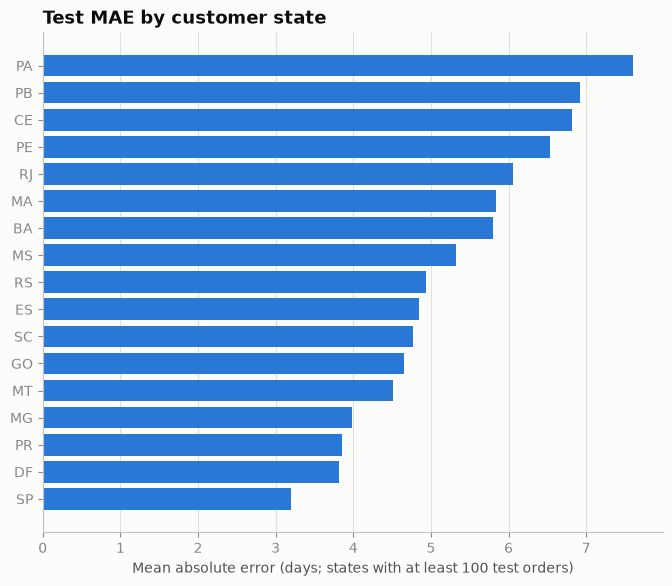

customer_state,SP,DF,PR,MG,MT,GO,SC,ES,RS,MS,BA,MA,RJ,PE,CE,PB,PA
orders,"8,058.00",378.00,"1,017.00","2,241.00",198.00,398.00,717.00,396.00,"1,019.00",139.00,617.00,159.00,"2,509.00",351.00,255.00,105.00,194.00
MAE,3.19,3.81,3.85,3.98,4.52,4.65,4.77,4.84,4.94,5.32,5.80,5.84,6.06,6.53,6.82,6.92,7.60


In [29]:
by_state = (err.groupby('customer_state').agg(orders=('abs_err', 'size'), MAE=('abs_err', 'mean'))
               .query('orders >= 100').sort_values('MAE'))
fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh(by_state.index, by_state['MAE'], color=BLUE)
ax.set_title('Test MAE by customer state')
ax.set_xlabel('Mean absolute error (days; states with at least 100 test orders)'); ax.grid(axis='y', visible=False)
plt.show()
by_state.round(2).T

**Insight:** Error follows geography. SP (the biggest state, 8,058 test orders) has the lowest MAE at 3.2 days, while PA (7.6), PB (7.0), CE (6.9) and PE (6.5) are about twice as high. RJ stands out: it has many orders (2,509) and an MAE of 6.1, so it is the single largest place to improve. Remote states have fewer orders and more variable shipping.

In [30]:
err['distance_band'] = pd.qcut(err['distance_km'], 5)
by_band = err.groupby('distance_band', observed=True).agg(orders=('abs_err', 'size'), MAE=('abs_err', 'mean'),
                                                          mean_actual=('total', 'mean'), bias=('resid', 'mean'))
by_month = (err.groupby('purchase_month').agg(orders=('abs_err', 'size'), MAE=('abs_err', 'mean'), bias=('resid', 'mean'))
               .query('orders >= 300'))
display(by_band.round(2))
by_month.round(2).T

,orders,MAE,mean_actual,bias
distance_band,,,,
"(-0.001, 113.307]",3831,2.78,6.61,1.01
"(113.307, 348.34]",3830,3.98,10.98,1.35
"(348.34, 531.633]",3831,4.28,12.42,1.45
"(531.633, 876.813]",3830,4.79,14.34,1.51
"(876.813, 4791.614]",3831,5.81,18.08,1.77


purchase_month,2017-02,2017-03,2017-04,2017-05,2017-06,2017-07,2017-08,2017-09,2017-10,2017-11,2017-12,2018-01,2018-02,2018-03,2018-04,2018-05,2018-06,2018-07,2018-08
orders,338.00,507.00,470.00,674.00,638.00,771.00,789.00,840.00,873.00,"1,464.00","1,145.00","1,377.00","1,367.00","1,414.00","1,326.00","1,376.00","1,192.00","1,242.00","1,246.00"
MAE,3.98,5.94,5.23,3.99,4.20,3.73,3.52,3.55,3.75,5.73,5.39,5.06,5.87,5.94,3.81,4.18,2.67,2.73,2.18
bias,-0.17,-0.07,2.61,1.23,1.82,1.57,1.36,0.96,0.79,2.41,1.81,1.79,2.67,2.77,1.01,1.79,-0.01,0.07,0.13


**Insight:**
- Error grows with distance: MAE is 2.8 days for the nearest 20% of orders and 5.8 for the farthest 20%, because longer routes have more that can go wrong.
- The bias is positive in every band (+1.0 to +1.8), meaning actual times are on average later than predicted.
- By month, the worst periods are **November 2017 to March 2018** (MAE 5.1-6.0, bias up to +2.7), the months in which delivery times rose. After June 2018 the MAE is only 2.2-2.7 with almost no bias. The model underestimates disruption periods, because it only knows the month, not that the network was overloaded.

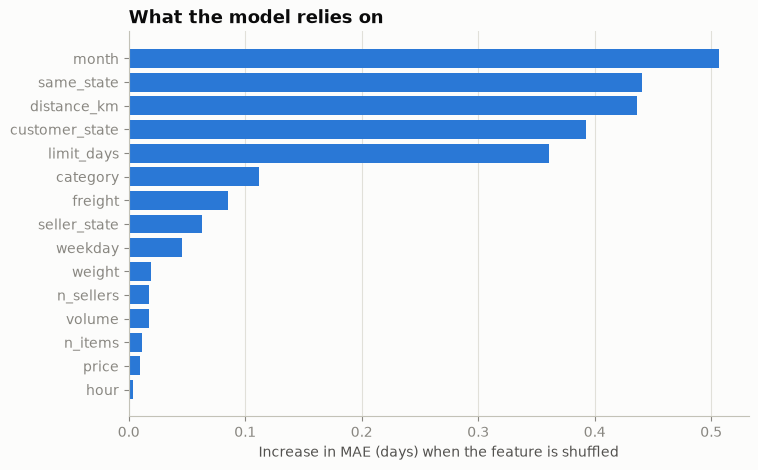

,month,same_state,distance_km,customer_state,limit_days,category,freight,seller_state,weekday,weight,n_sellers,volume,n_items,price,hour
MAE increase (days),0.51,0.44,0.44,0.39,0.36,0.11,0.08,0.06,0.05,0.02,0.02,0.02,0.01,0.01,0.00


In [31]:
sample = df_test.sample(6000, random_state=RANDOM_STATE)
pi = permutation_importance(final[('total', 'HistGradientBoosting')], sample[features], sample['total'],
                            scoring='neg_mean_absolute_error', n_repeats=3, random_state=RANDOM_STATE, n_jobs=2)
imp = pd.Series(pi.importances_mean, index=features).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(imp.index, imp.values, color=BLUE)
ax.set_title('What the model relies on')
ax.set_xlabel('Increase in MAE (days) when the feature is shuffled'); ax.grid(axis='y', visible=False)
plt.show()
imp.sort_values(ascending=False).to_frame('MAE increase (days)').T

**Insight:** The model relies mainly on five things: `month` (0.52 days of MAE added when shuffled), `same_state` (0.45), `distance_km` (0.43), `customer_state` (0.39) and `limit_days` (0.36). Everything else, including price, weight, volume and hour of day, adds almost nothing. Two caveats: (1) `month` is strong partly because the random split puts every month in both train and test; for forecasting future months, the model would not know about a new peak or an improvement in carriers. (2) `distance_km`, `same_state` and `customer_state` carry overlapping information, so their individual importance is shared.

## 14. Summary and saving the models

### Findings
- Olist's estimate is **12.7 days off on average** (23.7 days promised vs 12.6 days actual). Our best model is **4.3 days off**, a 66% improvement, using only information known at purchase.
- Delivery time is driven by **geography** (distance, same state, customer state), **the seller's shipping deadline** and **the time of year**. Product price, weight and size matter very little.
- Predicting handling and shipping separately gives no gain over predicting the total directly.
- The gradient boosting model beats Linear Regression (4.3 vs 5.1 days), but tuning adds little.

### Limits
- R² is 0.33: most of the remaining error comes from events that cannot be known at purchase (carrier delays, holidays, strikes).
- The model underestimates in disruption periods (Nov 2017 - Mar 2018) and in remote states.
- The data covers only 2017-2018.

### Next steps
- Add carrier and seller history features (for example a seller's past average handling time), computed only from earlier orders.
- Check performance by period before deployment, since delivery times shifted over time.

In [32]:
import os
os.makedirs('models', exist_ok=True)
for (t, name), m in final.items():
    tag = 'lr' if name.startswith('Linear') else 'hgb'
    joblib.dump(m, f'models/{tag}_{t}.joblib')
json.dump({'cat_cols': cat_cols, 'num_cols': num_cols, 'targets': targets}, open('models/features.json', 'w'), indent=2)
sorted(os.listdir('models'))

['features.json',
 'hgb_leg1.joblib',
 'hgb_leg2.joblib',
 'hgb_total.joblib',
 'lr_leg1.joblib',
 'lr_leg2.joblib',
 'lr_total.joblib']